In [4]:
!pip install --upgrade flax optax

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.5/532.5 kB 16.4 MB/s eta 0:00:00
  Attempting uninstall: flax
    Found existing installation: flax 0.11.2
    Uninstalling flax-0.11.2:
      Successfully uninstalled flax-0.11.2


In [ ]:
pip install trimesh

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 750.4/750.4 kB 17.5 MB/s eta 0:00:00


In [ ]:
!pip install polyhedral-gravity

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.0/876.0 kB 19.9 MB/s eta 0:00:00


In [ ]:
import numpy as np
import trimesh
from scipy.spatial import KDTree

# 1. Load the mesh using standard trimesh (already installed in Colab)
mesh = trimesh.load("/content/Eros Gaskell 50k poly.obj")
vertices = np.array(mesh.vertices)

print(f"Loaded mesh: {vertices.shape[0]} vertices.")

# 2. Build KDTree for quick distance estimation to the outer surface
tree = KDTree(vertices)

num_samples = 40000
buffer_km = 10.0
min_b, max_b = mesh.bounds

# 3. Uniformly sample in the bounding box
coords = np.random.uniform(
    min_b - buffer_km,
    max_b + buffer_km,
    size=(num_samples * 2, 3)
)

# 4. Strict geometric exterior filter:
# Distance to nearest surface vertex must be positive and outside local surface normal
# Quick proxy: radial distance check + nearest-neighbor clearance
radii = np.linalg.norm(coords, axis=1)
max_body_radius = np.linalg.norm(vertices, axis=1).max()

# Points definitely outside the circumscribing sphere:
outer_mask = radii > max_body_radius

# For points within the outer radius, keep those well-clear of vertices
dists, _ = tree.query(coords[~outer_mask])
near_exterior_mask = dists > 0.5  # at least 500m away from nearest vertex

valid_exterior = np.vstack([
    coords[outer_mask],
    coords[~outer_mask][near_exterior_mask]
])[:num_samples]

print(f"Sampled {len(valid_exterior)} valid exterior vacuum coordinates.")
np.save("eros_exterior_coords.npy", valid_exterior)

Loaded mesh: 24578 vertices.
Sampled 40000 valid exterior vacuum coordinates.


In [1]:
import numpy as np
import trimesh
from tqdm import tqdm
from polyhedral_gravity import Polyhedron, GravityEvaluable, PolyhedronIntegrity

print("1. Generating 50,000 Precision Near-Field Coordinates...")
mesh = trimesh.load("/content/Eros Gaskell 50k poly.obj")

def generate_tiered_points(mesh, num_points, min_dist_km, max_dist_km):
    surface_pts, face_indices = trimesh.sample.sample_surface(mesh, num_points)
    normals = mesh.face_normals[face_indices]
    offsets = np.random.uniform(min_dist_km, max_dist_km, size=(num_points, 1))
    return surface_pts + (normals * offsets)

# TIER 1: The Danger Zone (50 meters to 1 km)
tier_1 = generate_tiered_points(mesh, 25000, 0.05, 1.0)

# TIER 2: The Transition Zone (1 km to 5 km)
tier_2 = generate_tiered_points(mesh, 15000, 1.0, 5.0)

# TIER 3: The Mid-Field Envelope (5 km to 15 km)
tier_3 = generate_tiered_points(mesh, 10000, 5.0, 15.0)

# Combine and convert to meters
train_coords_km = np.vstack([tier_1, tier_2, tier_3])
train_coords_m = train_coords_km * 1000.0

print(f"Generated {len(train_coords_m)} targeted conformal points.")

print("\n2. Calculating Ground Truth (C++ Polyhedron Engine)...")
vertices_m = np.array(mesh.vertices) * 1000.0
eros_polyhedron = Polyhedron(
    polyhedral_source=(vertices_m, np.array(mesh.faces)),
    density=2670.0,
    integrity_check=PolyhedronIntegrity.DISABLE
)
evaluable = GravityEvaluable(eros_polyhedron)

train_true_acc = []
for i in tqdm(range(0, len(train_coords_m), 1000), desc="C++ Engine Working"):
    chunk = train_coords_m[i:i + 1000]
    results = evaluable(chunk, parallel=True)
    train_true_acc.extend([res[1] for res in results])

train_true_acc = np.array(train_true_acc)

# Overwrite the old garbage data
np.save("eros_exterior_coords.npy", train_coords_km)
np.save("eros_true_accelerations.npy", train_true_acc)
print("\nPrecision near-field training data saved successfully.")

1. Generating 50,000 Precision Near-Field Coordinates...
Generated 50000 targeted conformal points.

2. Calculating Ground Truth (C++ Polyhedron Engine)...


C++ Engine Working: 100%|██████████| 50/50 [12:12<00:00, 14.64s/it]


Precision near-field training data saved successfully.


In [1]:
import jax
import jax.numpy as jnp
import flax.linen as nn
import numpy as np
import optax

# 1. Load the new Near-Field Data
coords_m = np.load("eros_exterior_coords.npy") * 1000.0
true_acc = np.load("eros_true_accelerations.npy")

R_norm = np.max(np.linalg.norm(coords_m, axis=1))
A_norm = np.max(np.linalg.norm(true_acc, axis=1))
coords_scaled = coords_m / R_norm
acc_scaled = true_acc / A_norm

furthest_idx = np.argmax(np.linalg.norm(coords_scaled, axis=1))
mu_scaled = np.linalg.norm(acc_scaled[furthest_idx]) * (np.linalg.norm(coords_scaled[furthest_idx]) ** 2)
print(f"R_norm: {R_norm/1000:.2f} km | A_norm: {A_norm:.6f} m/s^2 | Scaled Mu: {mu_scaled:.6f}")

# 2. Define the Near-Field Architecture
class PINNGravityModel(nn.Module):
    @nn.compact
    def __call__(self, x):
        r = jnp.linalg.norm(x)
        z = nn.Dense(128)(x)
        z = nn.gelu(z)
        z = nn.Dense(128)(z)
        z = nn.gelu(z)
        z = nn.Dense(128)(z)
        z = nn.gelu(z)
        z = nn.Dense(128)(z)
        z = nn.gelu(z)
        u_nn = nn.Dense(1)(z)
        u_nn = jnp.squeeze(u_nn)

        u_bc = mu_scaled / (r + 1e-8)

        # Switch pushed to 1.1 to protect the near-field data
        h_r = 0.5 * (1.0 + jnp.tanh(10.0 * (r - 1.1)))

        return (1.0 - h_r) * u_nn + (h_r) * u_bc

model = PINNGravityModel()
params = model.init(jax.random.PRNGKey(42), jnp.array([0.5, 0.5, 0.5]))

# 3. JAX Setup
predict_acceleration = jax.grad(lambda p, x: model.apply(p, x), argnums=1)
batched_physics_acc = jax.vmap(lambda p, x: -predict_acceleration(p, x), in_axes=(None, 0))

@jax.jit
def loss_fn(params, x_batch, true_acc_batch):
    pred = batched_physics_acc(params, x_batch)
    diff = jnp.linalg.norm(true_acc_batch - pred, axis=1)
    true = jnp.linalg.norm(true_acc_batch, axis=1)
    return jnp.mean((diff / (true + 1e-8)) * 100.0)

optimizer = optax.adam(learning_rate=1e-3)
opt_state = optimizer.init(params)

@jax.jit
def update_step(params, opt_state, x_batch, true_acc_batch):
    loss, grads = jax.value_and_grad(loss_fn)(params, x_batch, true_acc_batch)
    updates, opt_state = optimizer.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, loss

# 4. Train for 500 Epochs
batch_size = 512
X_train, Y_train = jnp.array(coords_scaled), jnp.array(acc_scaled)

print("\nStarting 500-Epoch Training on Landing Zone Data...")
for epoch in range(500):
    indices = np.random.permutation(len(coords_scaled))
    epoch_loss, batches = 0.0, 0
    for i in range(0, len(coords_scaled), batch_size):
        batch_idx = indices[i:i+batch_size]
        params, opt_state, loss = update_step(params, opt_state, X_train[batch_idx], Y_train[batch_idx])
        epoch_loss += loss
        batches += 1
    if epoch % 30 == 0 or epoch == 299:
        print(f"Epoch {epoch:03d} | Mean Percent Error: {epoch_loss / batches:.2f}%")

R_norm: 32.05 km | A_norm: 0.005617 m/s^2 | Scaled Mu: 0.093294

Starting 500-Epoch Training on Landing Zone Data...
Epoch 000 | Mean Percent Error: 51.16%
Epoch 030 | Mean Percent Error: 4.14%
Epoch 060 | Mean Percent Error: 2.10%
Epoch 090 | Mean Percent Error: 1.57%
Epoch 120 | Mean Percent Error: 1.18%
Epoch 150 | Mean Percent Error: 1.12%
Epoch 180 | Mean Percent Error: 0.89%
Epoch 210 | Mean Percent Error: 0.83%
Epoch 240 | Mean Percent Error: 0.73%
Epoch 270 | Mean Percent Error: 0.80%
Epoch 299 | Mean Percent Error: 0.74%
Epoch 300 | Mean Percent Error: 0.73%
Epoch 330 | Mean Percent Error: 0.82%
Epoch 360 | Mean Percent Error: 0.81%
Epoch 390 | Mean Percent Error: 0.65%
Epoch 420 | Mean Percent Error: 0.72%
Epoch 450 | Mean Percent Error: 0.70%
Epoch 480 | Mean Percent Error: 0.54%


In [3]:
import numpy as np
import trimesh
from tqdm import tqdm
from polyhedral_gravity import Polyhedron, GravityEvaluable, PolyhedronIntegrity
import jax.numpy as jnp

print("1. Generating 15,000 Tiered Test Coordinates (5,000 per Tier)...")
mesh = trimesh.load("/content/Eros Gaskell 50k poly.obj")

def generate_tiered_points(mesh, num_points, min_dist_km, max_dist_km):
    surface_pts, face_indices = trimesh.sample.sample_surface(mesh, num_points)
    normals = mesh.face_normals[face_indices]
    offsets = np.random.uniform(min_dist_km, max_dist_km, size=(num_points, 1))
    return surface_pts + (normals * offsets)

# Generate 5,000 completely unseen test points for each tier
test_tier_1_km = generate_tiered_points(mesh, 5000, 0.05, 1.0)
test_tier_2_km = generate_tiered_points(mesh, 5000, 1.0, 5.0)
test_tier_3_km = generate_tiered_points(mesh, 5000, 5.0, 15.0)

tiers = [
    ("Tier 1 (50m - 1km)  [Danger Zone]", test_tier_1_km),
    ("Tier 2 (1km - 5km)  [Transition Zone]", test_tier_2_km),
    ("Tier 3 (5km - 15km) [Mid-Field Envelope]", test_tier_3_km)
]

print("\n2. Initializing C++ Polyhedron Engine...")
vertices_m = np.array(mesh.vertices) * 1000.0
eros_polyhedron = Polyhedron(
    polyhedral_source=(vertices_m, np.array(mesh.faces)),
    density=2670.0,
    integrity_check=PolyhedronIntegrity.DISABLE
)
evaluable = GravityEvaluable(eros_polyhedron)

def evaluate_tier(name, test_coords_km):
    test_coords_m = test_coords_km * 1000.0

    # A. Calculate C++ Ground Truth
    true_acc = []
    for i in tqdm(range(0, len(test_coords_m), 1000), desc=f"Evaluating {name.split()[1]}"):
        chunk = test_coords_m[i:i + 1000]
        results = evaluable(chunk, parallel=True)
        true_acc.extend([res[1] for res in results])
    true_acc = np.array(true_acc)

    # B. Run PINN Inference
    X_test_scaled = jnp.array(test_coords_m / R_norm)
    pred_acc_scaled = batched_physics_acc(params, X_test_scaled)
    pred_acc_real = np.array(pred_acc_scaled) * A_norm

    # C. Calculate Metrics
    error_vectors = true_acc - pred_acc_real
    error_magnitudes_sq = np.sum(error_vectors**2, axis=1)
    true_magnitudes_sq = np.sum(true_acc**2, axis=1)

    diff_norm = np.sqrt(error_magnitudes_sq)
    true_norm = np.sqrt(true_magnitudes_sq)

    mse = np.mean(error_magnitudes_sq)
    rmse = np.sqrt(mse)
    mpe = np.mean((diff_norm / (true_norm + 1e-8)) * 100.0)
    relative_l2 = np.sqrt(np.sum(error_magnitudes_sq)) / np.sqrt(np.sum(true_magnitudes_sq))

    return mpe, mse, rmse, relative_l2

print("\n3. Running Inference and Calculating Metrics...")
results = {}
for name, coords in tiers:
    results[name] = evaluate_tier(name, coords)

print("\n===========================================================")
print(" 🚀 ULTIMATE TIERED VALIDATION RESULTS (5,000 pts/tier)")
print("===========================================================")
for name, metrics in results.items():
    mpe, mse, rmse, rel_l2 = metrics
    print(f"\n{name}")
    print(f"  Mean Percent Error : {mpe:.4f} %")
    print(f"  Mean Squared Error : {mse:.12f} (m/s^2)^2")
    print(f"  Root Mean Sq Error : {rmse:.8f} m/s^2")
    print(f"  Relative L2 Error  : {rel_l2:.6f}")
print("===========================================================")

1. Generating 15,000 Tiered Test Coordinates (5,000 per Tier)...

2. Initializing C++ Polyhedron Engine...

3. Running Inference and Calculating Metrics...


Evaluating 3: 100%|██████████| 5/5 [01:13<00:00, 14.70s/it]


 🚀 ULTIMATE TIERED VALIDATION RESULTS (5,000 pts/tier)

Tier 1 (50m - 1km)  [Danger Zone]
  Mean Percent Error : 0.7210 %
  Mean Squared Error : 0.000000001821 (m/s^2)^2
  Root Mean Sq Error : 0.00004267 m/s^2
  Relative L2 Error  : 0.009045

Tier 2 (1km - 5km)  [Transition Zone]
  Mean Percent Error : 0.4683 %
  Mean Squared Error : 0.000000000263 (m/s^2)^2
  Root Mean Sq Error : 0.00001622 m/s^2
  Relative L2 Error  : 0.005144

Tier 3 (5km - 15km) [Mid-Field Envelope]
  Mean Percent Error : 0.4113 %
  Mean Squared Error : 0.000000000043 (m/s^2)^2
  Root Mean Sq Error : 0.00000658 m/s^2
  Relative L2 Error  : 0.004595


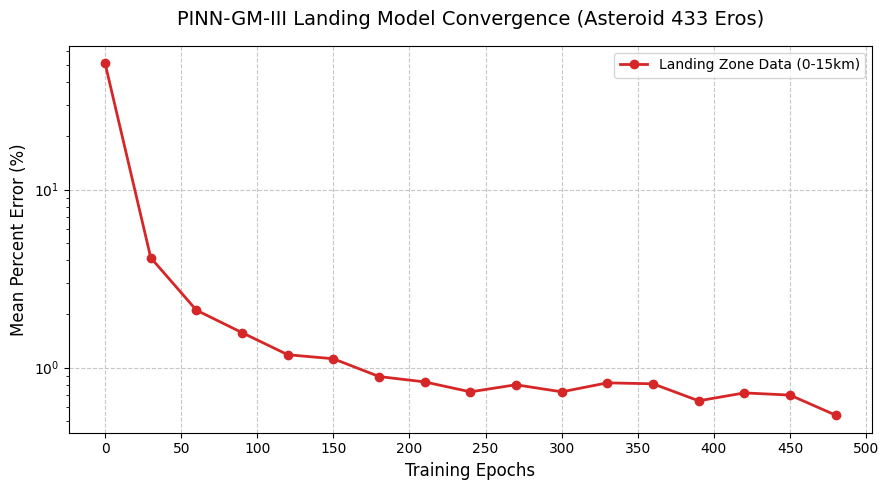

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Your exact 500-epoch training loss outputs
epochs = np.array([0, 30, 60, 90, 120, 150, 180, 210, 240, 270, 300, 330, 360, 390, 420, 450, 480])
mpe_loss = np.array([51.16, 4.14, 2.10, 1.57, 1.18, 1.12, 0.89, 0.83, 0.73, 0.80, 0.73, 0.82, 0.81, 0.65, 0.72, 0.70, 0.54])

plt.figure(figsize=(9, 5))
plt.plot(epochs, mpe_loss, marker='o', linestyle='-', color='#d62728', linewidth=2, markersize=6, label="Landing Zone Data (0-15km)")

plt.title("PINN-GM-III Landing Model Convergence (Asteroid 433 Eros)", fontsize=14, pad=15)
plt.xlabel("Training Epochs", fontsize=12)
plt.ylabel("Mean Percent Error (%)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.yscale('log')
plt.xticks(np.arange(0, 501, 50))
plt.legend()

plt.tight_layout()
plt.show()

In [5]:
from flax.serialization import msgpack_serialize
from google.colab import files
import os

# Serialize the trained JAX/Flax parameters
serialized_params = msgpack_serialize(params)

# Write to a binary file with a new, descriptive name
filename = "eros_pinn_landing_model_tier1_0_72mpe.msgpack"
with open(filename, "wb") as f:
    f.write(serialized_params)

print(f"Landing Model weights successfully saved to {filename} ({os.path.getsize(filename) / 1024:.2f} KB)")

# Trigger direct download to your local machine
files.download(filename)

Landing Model weights successfully saved to eros_pinn_landing_model_tier1_0_72mpe.msgpack (196.32 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import numpy as np
import plotly.graph_objects as go
import jax.numpy as jnp
import trimesh

print("Preparing 3,000-point validation visualization...")

# 1. Load the mesh for the center trace
mesh = trimesh.load("/content/Eros Gaskell 50k poly.obj")
vertices = np.array(mesh.vertices)
faces = np.array(mesh.faces)
vertices_km = vertices

# 2. Randomly sample 1,000 points from your existing tier arrays
N_vis = 1000
pts_t1 = test_tier_1_km[np.random.choice(len(test_tier_1_km), N_vis, replace=False)]
pts_t2 = test_tier_2_km[np.random.choice(len(test_tier_2_km), N_vis, replace=False)]
pts_t3 = test_tier_3_km[np.random.choice(len(test_tier_3_km), N_vis, replace=False)]

tiers_vis = [
    ("Tier 1 (50m - 1km)", pts_t1, '#d62728'),    # Red for Danger Zone
    ("Tier 2 (1km - 5km)", pts_t2, '#ff7f0e'),    # Orange for Transition
    ("Tier 3 (5km - 15km)", pts_t3, '#1f77b4')    # Blue for Mid-Field
]

# 3. Setup the 3D Figure
fig = go.Figure()

# Add the Asteroid Mesh
fig.add_trace(go.Mesh3d(
    x=vertices_km[:, 0], y=vertices_km[:, 1], z=vertices_km[:, 2],
    i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
    color='gray', opacity=1.0, name="433 Eros",
    lighting=dict(ambient=0.4, diffuse=0.8, roughness=0.5),
    hoverinfo='skip' # Don't show hover data for the rock itself
))

# 4. Evaluate and Plot each Tier
for name, pts_km, color in tiers_vis:

    # A. C++ Ground Truth (True Value)
    pts_m = pts_km * 1000.0
    results = evaluable(pts_m, parallel=True)
    true_acc = np.array([res[1] for res in results])
    true_mag = np.linalg.norm(true_acc, axis=1)

    # B. JAX PINN Inference (Model Value)
    pts_scaled = jnp.array(pts_m / R_norm)
    pred_scaled = batched_physics_acc(params, pts_scaled)
    pred_acc = np.array(pred_scaled) * A_norm
    pred_mag = np.linalg.norm(pred_acc, axis=1)

    # C. Calculate absolute error for hover context
    error_mag = np.abs(true_mag - pred_mag)

    # Stack data for the hover template
    # Column 0: PINN, Column 1: True, Column 2: Error
    hover_data = np.column_stack((pred_mag, true_mag, error_mag))

    # D. Add to 3D Plot
    fig.add_trace(go.Scatter3d(
        x=pts_km[:, 0], y=pts_km[:, 1], z=pts_km[:, 2],
        mode='markers',
        marker=dict(size=3, color=color, opacity=0.8),
        name=name,
        customdata=hover_data,
        hovertemplate=(
            "<b>X:</b> %{x:.2f} km<br>" +
            "<b>Y:</b> %{y:.2f} km<br>" +
            "<b>Z:</b> %{z:.2f} km<br><br>" +
            "<b>PINN Model:</b> %{customdata[0]:.6f} m/s²<br>" +
            "<b>Actual True:</b>  %{customdata[1]:.6f} m/s²<br>" +
            "<b>Abs Error:</b>    %{customdata[2]:.8f} m/s²<br>" +
            "<extra></extra>"
        )
    ))

# 5. Format and display
fig.update_layout(
    title="PINN Landing Model vs Ground Truth (3,000 Points)",
    scene=dict(
        aspectmode='data', # Keeps the asteroid scale physically accurate
        xaxis=dict(title="X (km)"),
        yaxis=dict(title="Y (km)"),
        zaxis=dict(title="Z (km)")
    ),
    legend=dict(
        x=0.02, y=0.98,
        bordercolor="Black", borderwidth=1,
        itemsizing='constant'
    ),
    margin=dict(l=0, r=0, b=0, t=50)
)

fig.show()

Preparing 3,000-point validation visualization...
